# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Hilal Tsabitul Azmi Arba'i | 5054251008 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from matplotlib.lines import Line2D
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)

# Pengaturan tampilan agar plot dan tabel mudah dibaca
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)

# Palet warna tetap per segmen agar legenda konsisten di semua plot
WARNA_SEGMEN = {
    "Rendah–rendah": "#4C72B0",
    "Rendah–menengah": "#DD8452",
    "Rendah–tinggi": "#55A868",
    "Menengah–rendah": "#C44E52",
    "Menengah–menengah": "#8172B3",
    "Menengah–tinggi": "#937860",
    "Tinggi–rendah": "#DA8BC3",
    "Tinggi–menengah": "#8C8C8C",
    "Tinggi–tinggi": "#CCB974",
}
WARNA_NOISE = "#222222"


def nama_segmen(median_income, median_spending):
    """Beri nama segmen berdasarkan median pendapatan dan spending."""
    if median_income < 45:
        tingkat_pendapatan = "Rendah"
    elif median_income < 65:
        tingkat_pendapatan = "Menengah"
    else:
        tingkat_pendapatan = "Tinggi"

    if median_spending < 35:
        tingkat_spending = "rendah"
    elif median_spending < 60:
        tingkat_spending = "menengah"
    else:
        tingkat_spending = "tinggi"

    return f"{tingkat_pendapatan}–{tingkat_spending}"


def petakan_segmen(X_asli, labels):
    """Kembalikan dict label -> (nama segmen, warna) yang konsisten."""
    profil = X_asli.groupby(labels).median()
    peta = {}
    for label, baris in profil.iterrows():
        if label == -1:
            peta[label] = ("Noise", WARNA_NOISE)
        else:
            nama = nama_segmen(
                baris["Annual Income (k$)"], baris["Spending Score (1-100)"]
            )
            peta[label] = (nama, WARNA_SEGMEN.get(nama, "#7F7F7F"))
    return peta


def warna_plot(labels, peta):
    """Warna per label; pakai warna segmen jika nama segmen unik.

    Jika ada beberapa cluster yang jatuh ke nama segmen yang sama (misalnya
    pada model awal yang belum memisahkan segmen dengan rapi), warna segmen
    akan sama dan legenda menjadi ambigu. Untuk kasus itu, gunakan palet
    khusus agar setiap cluster tetap punya warna berbeda.
    """
    label_unik = sorted(set(labels) - {-1})
    nama_unik = [peta[label][0] for label in label_unik]
    if len(nama_unik) == len(set(nama_unik)):
        return {label: peta[label][1] for label in label_unik}

    palet = sns.color_palette("husl", len(label_unik))
    return {label: palet[i] for i, label in enumerate(label_unik)}


In [2]:
# Muat dataset Mall_Customers.csv
df = pd.read_csv("Mall_Customers.csv")

print("5 baris pertama dataset:")
display(df.head())

print(f"\nJumlah baris: {df.shape[0]}, jumlah kolom: {df.shape[1]}")

print("\nTipe data tiap kolom:")
print(df.dtypes)

print("\nStatistik deskriptif:")
display(df.describe().T)

print("\nJumlah missing value per kolom:")
print(df.isna().sum())
print(f"Total missing value: {df.isna().sum().sum()}")

print(f"\nJumlah baris duplikat: {df.duplicated().sum()}")

5 baris pertama dataset:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Jumlah baris: 200, jumlah kolom: 5

Tipe data tiap kolom:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
CustomerID,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0



Jumlah missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Total missing value: 0

Jumlah baris duplikat: 0


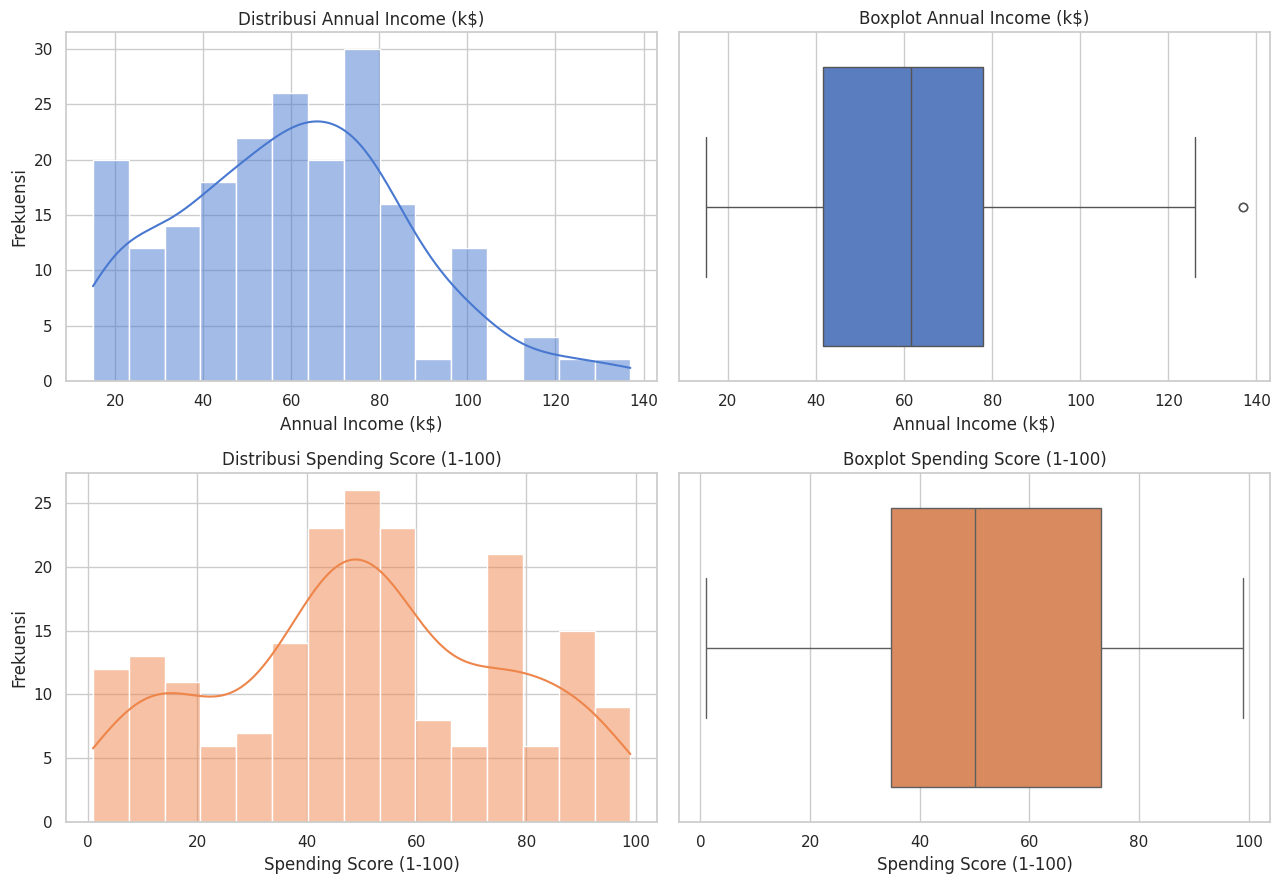

Ringkasan distribusi dan outlier (aturan IQR):
- Annual Income (k$): rentang 15–137, median 61.5, rata-rata 60.56, batas IQR [-13.25, 132.75], jumlah outlier 2
- Spending Score (1-100): rentang 1–99, median 50.0, rata-rata 50.20, batas IQR [-22.62, 130.38], jumlah outlier 0


In [3]:
# Distribusi Annual Income (k$) dan Spending Score (1-100)
features = ["Annual Income (k$)", "Spending Score (1-100)"]
colors = sns.color_palette("muted")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for i, col in enumerate(features):
    # Histogram + KDE untuk melihat bentuk distribusi
    sns.histplot(df[col], bins=15, kde=True, color=colors[i], ax=axes[i, 0])
    axes[i, 0].set_title(f"Distribusi {col}")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Frekuensi")

    # Boxplot untuk melihat rentang dan kemungkinan outlier
    sns.boxplot(x=df[col], color=colors[i], ax=axes[i, 1])
    axes[i, 1].set_title(f"Boxplot {col}")
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

# Ringkasan rentang dan deteksi outlier dengan aturan IQR (1,5 x IQR)
print("Ringkasan distribusi dan outlier (aturan IQR):")
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outlier = ((df[col] < lower) | (df[col] > upper)).sum()
    print(
        f"- {col}: rentang {df[col].min()}–{df[col].max()}, "
        f"median {df[col].median():.1f}, rata-rata {df[col].mean():.2f}, "
        f"batas IQR [{lower:.2f}, {upper:.2f}], jumlah outlier {n_outlier}"
    )

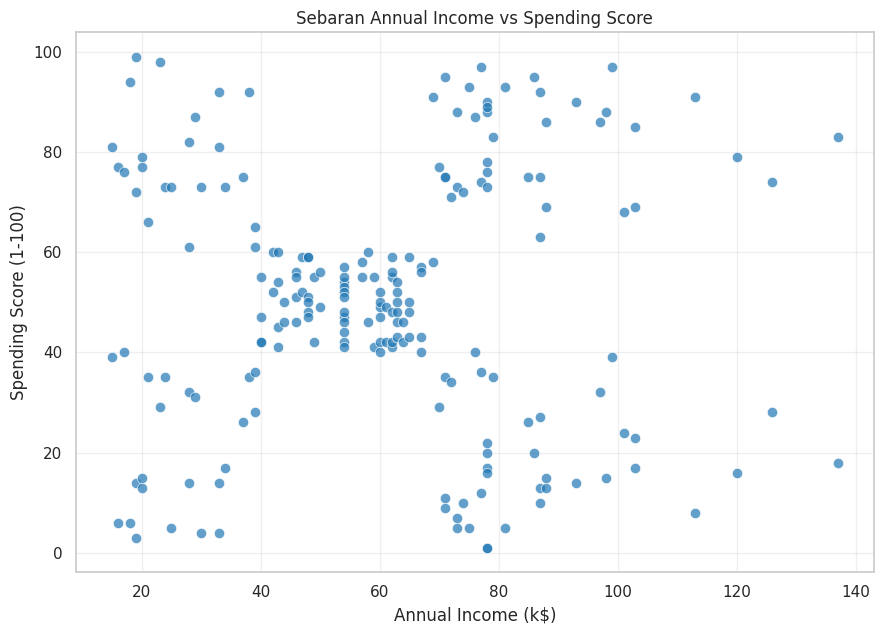

Korelasi Pearson Annual Income vs Spending Score: 0.0099


In [4]:
# Scatter plot dua fitur utama tanpa warna label
plt.figure(figsize=(9, 6.5))
plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    s=55,
    alpha=0.7,
    color="tab:blue",
    edgecolor="white",
    linewidth=0.6,
)

plt.title("Sebaran Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Korelasi linear sebagai gambaran awal hubungan kedua fitur
print(
    "Korelasi Pearson Annual Income vs Spending Score: "
    f"{df['Annual Income (k$)'].corr(df['Spending Score (1-100)']):.4f}"
)

## Jawaban EDA

- **Missing value dan baris duplikat:** dataset berisi **200 baris dan 5 kolom**, dengan **0 missing value** dan **0 baris duplikat**. Karena itu, tidak ada data yang perlu dihapus pada tahap ini.
- **Rentang pendapatan dan spending score:** `Annual Income (k$)` berkisar **15–137** (rata-rata 60,56; median 61,5), sedangkan `Spending Score (1-100)` berkisar **1–99** (rata-rata 50,20; median 50). Kedua fitur cukup menyebar dan relatif simetris. Berdasarkan aturan IQR, terdapat **2 outlier** pada pendapatan, yaitu dua pelanggan dengan pendapatan 137 k$, tetapi nilainya masih wajar untuk konteks pelanggan pusat perbelanjaan.
- **Kelompok yang terpisah:** scatter plot memperlihatkan pola pengelompokan yang cukup jelas. Terlihat kelompok pendapatan rendah dengan spending rendah dan tinggi, kelompok pendapatan menengah dengan spending menengah, serta kelompok pendapatan tinggi dengan spending rendah dan tinggi. Secara visual tampak sekitar **lima kelompok**, meskipun batas antarkelompok tidak selalu tegas. Korelasi kedua fitur sangat lemah (≈0,01), sehingga kelompok tidak terbentuk dari hubungan linear, melainkan dari kombinasi tingkat pendapatan dan spending.

# 2. Preprocessing

In [5]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan
n_missing = df.isna().sum().sum()
n_duplikat = df.duplicated().sum()
print(f"Missing value sebelum penanganan: {n_missing}")
print(f"Baris duplikat sebelum penanganan: {n_duplikat}")

if n_missing > 0:
    df = df.dropna().reset_index(drop=True)
    print("Baris dengan missing value telah dihapus.")

if n_duplikat > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Baris duplikat telah dihapus.")

print(f"Jumlah data setelah penanganan: {df.shape[0]} baris")

# CustomerID hanya identitas, sehingga tidak dimasukkan sebagai fitur clustering
# Gender juga tidak digunakan pada eksperimen utama (dua fitur numerik)
fitur = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[fitur].copy()

print(f"\nFitur yang digunakan: {fitur}")
print(f"Dimensi X: {X.shape}")
display(X.head())

Missing value sebelum penanganan: 0
Baris duplikat sebelum penanganan: 0
Jumlah data setelah penanganan: 200 baris

Fitur yang digunakan: ['Annual Income (k$)', 'Spending Score (1-100)']
Dimensi X: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [6]:
# Feature scaling menggunakan StandardScaler (z-score)
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index,
)

print("Beberapa baris X_scaled:")
display(X_scaled.head())

print("\nStatistik deskriptif X_scaled:")
display(X_scaled.describe().T)

print("\nRata-rata X_scaled (seharusnya mendekati 0):")
print(X_scaled.mean().round(10))

print("\nStandar deviasi X_scaled populasi (seharusnya 1):")
print(X_scaled.std(ddof=0).round(10))

Beberapa baris X_scaled:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Statistik deskriptif X_scaled:


,count,mean,std,min,25%,50%,75%,max
Annual Income (k$),200.0,-2.131628e-16,1.002509,-1.738999,-0.727509,0.035879,0.665675,2.917671
Spending Score (1-100),200.0,-1.465494e-16,1.002509,-1.910021,-0.599793,-0.007764,0.885132,1.894492



Rata-rata X_scaled (seharusnya mendekati 0):
Annual Income (k$)       -0.0
Spending Score (1-100)   -0.0
dtype: float64

Standar deviasi X_scaled populasi (seharusnya 1):
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64


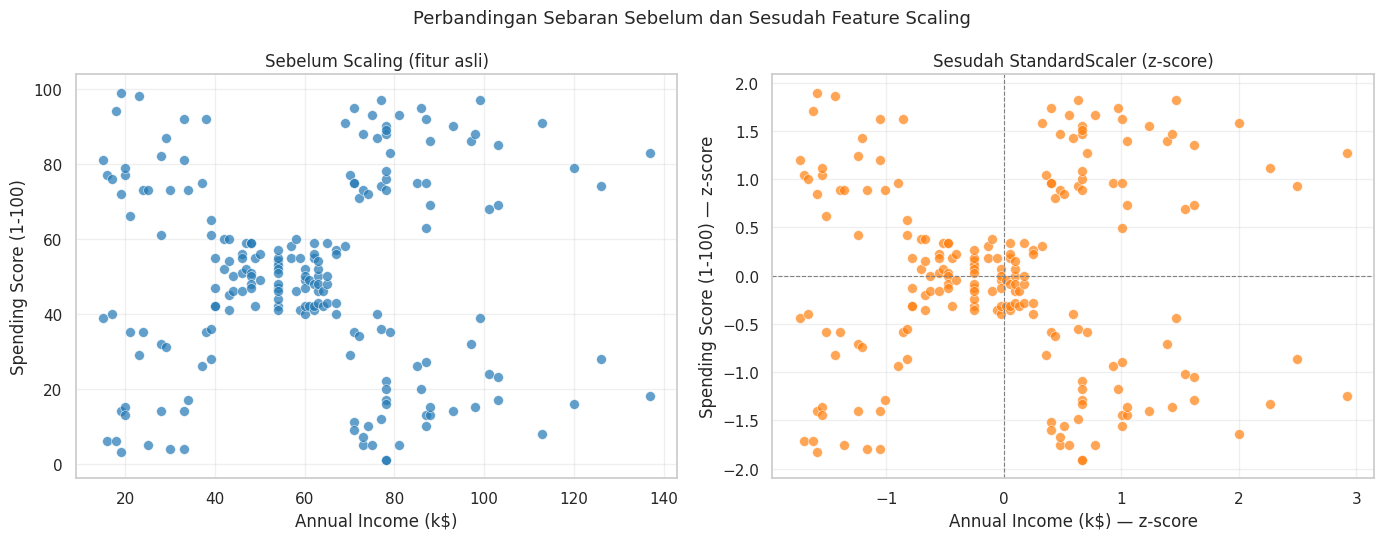

In [7]:
# Scatter plot sebelum dan sesudah scaling
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"],
    s=50,
    alpha=0.7,
    color="tab:blue",
    edgecolor="white",
    linewidth=0.5,
)
axes[0].set_title("Sebelum Scaling (fitur asli)")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(
    X_scaled["Annual Income (k$)"],
    X_scaled["Spending Score (1-100)"],
    s=50,
    alpha=0.7,
    color="tab:orange",
    edgecolor="white",
    linewidth=0.5,
)
axes[1].set_title("Sesudah StandardScaler (z-score)")
axes[1].set_xlabel("Annual Income (k$) — z-score")
axes[1].set_ylabel("Spending Score (1-100) — z-score")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].grid(True, alpha=0.3)

plt.suptitle("Perbandingan Sebaran Sebelum dan Sesudah Feature Scaling", fontsize=13)
plt.tight_layout()
plt.show()

**Mengapa feature scaling penting?**

- `Annual Income (k$)` dan `Spending Score (1-100)` berada pada satuan dan skala pengukuran yang berbeda. Pada dataset ini standar deviasinya kebetulan berdekatan (≈26,26 dan ≈25,82), tetapi tanpa scaling perbedaan skala tetap berpotensi membuat salah satu fitur lebih dominan saat jarak dihitung.
- DBSCAN dan BIRCH bekerja dengan jarak Euclidean. Jika satu fitur memiliki rentang atau varians jauh lebih besar, fitur tersebut akan mendominasi nilai `eps`/`threshold` sehingga cluster yang terbentuk menjadi tidak seimbang. Setelah `StandardScaler`, satu satuan jarak berarti satu simpangan baku pada masing-masing fitur, sehingga `eps` dan `threshold` dapat dibandingkan secara adil.
- GMM mengasumsikan bentuk distribusi dan matriks kovarians. Fitur dengan skala yang tidak sebanding dapat membuat estimasi kovarians kurang stabil; scaling membuat inisialisasi dan interpretasi parameter antarfitur lebih konsisten.
- Scaling tidak mengubah bentuk sebaran karena hanya melakukan translasi dan perubahan skala per fitur. Pola kelompok pada scatter plot tetap sama; yang berubah adalah satuan sumbu dan kontribusi tiap fitur terhadap jarak.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Kedua fitur dipilih karena mewakili dua dimensi utama segmentasi pelanggan: **kemampuan finansial** (pendapatan tahunan) dan **perilaku belanja** (spending score). Kombinasi keduanya membentuk pola yang cukup jelas pada scatter plot, sehingga cocok untuk membandingkan algoritma clustering berbasis kepadatan, hierarki, dan probabilistik. Keduanya juga numerik kontinu sehingga dapat langsung di-scaling.

`CustomerID` tidak digunakan karena hanya nomor identitas unik untuk setiap pelanggan. Nilainya tidak memiliki makna besar-kecil secara substantif; jika dimasukkan sebagai fitur, jarak antar-pelanggan akan didominasi oleh urutan ID dan cluster yang terbentuk tidak bermakna. `Gender` juga tidak digunakan pada eksperimen utama agar fokus pada dua fitur numerik sesuai petunjuk tugas; kolom tersebut dapat dipakai untuk interpretasi tambahan setelah model selesai.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Jalankan DBSCAN pada X_scaled dengan parameter awal
model_dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = model_dbscan.fit_predict(X_scaled)

print(f"DBSCAN dijalankan dengan eps={model_dbscan.eps}, min_samples={model_dbscan.min_samples}")
print("Label unik yang terbentuk:", np.unique(labels_dbscan))

DBSCAN dijalankan dengan eps=0.3, min_samples=5
Label unik yang terbentuk: [-1  0  1  2  3  4  5  6]


In [9]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN
print("Jumlah anggota tiap label DBSCAN:")
for label in sorted(set(labels_dbscan)):
    jumlah = int((labels_dbscan == label).sum())
    if label == -1:
        print(f"  Noise (label -1): {jumlah}")
    else:
        print(f"  Cluster {label}: {jumlah}")

# Hitung cluster tanpa memasukkan noise dan hitung titik noise
n_clusters_dbscan = len(set(labels_dbscan) - {-1})
n_noise_dbscan = int((labels_dbscan == -1).sum())

print(f"\nJumlah cluster (tanpa noise): {n_clusters_dbscan}")
print(f"Jumlah titik noise (label -1): {n_noise_dbscan}")
print(f"Persentase noise: {n_noise_dbscan / len(labels_dbscan) * 100:.1f}%")

Jumlah anggota tiap label DBSCAN:
  Noise (label -1): 35
  Cluster 0: 12
  Cluster 1: 5
  Cluster 2: 7
  Cluster 3: 88
  Cluster 4: 30
  Cluster 5: 14
  Cluster 6: 9

Jumlah cluster (tanpa noise): 7
Jumlah titik noise (label -1): 35
Persentase noise: 17.5%


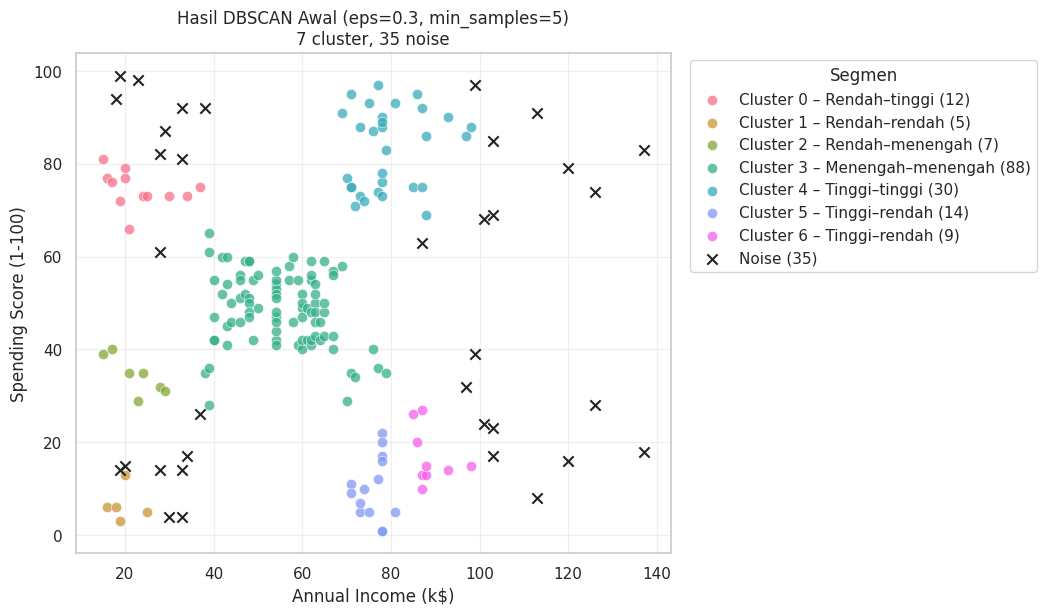

In [10]:
# Scatter plot hasil DBSCAN pada fitur asli agar mudah diinterpretasikan
peta_dbscan = petakan_segmen(X, labels_dbscan)
warna_dbscan = warna_plot(labels_dbscan, peta_dbscan)

fig, ax = plt.subplots(figsize=(10, 6.5))
for label in sorted(set(labels_dbscan), key=lambda x: (x == -1, x)):
    mask = labels_dbscan == label
    nama = peta_dbscan[label][0]
    warna = WARNA_NOISE if label == -1 else warna_dbscan[label]
    if label == -1:
        ax.scatter(
            X.loc[mask, "Annual Income (k$)"],
            X.loc[mask, "Spending Score (1-100)"],
            s=55, c=warna, marker="x", linewidths=1.5,
            label=f"Noise ({mask.sum()})",
        )
    else:
        ax.scatter(
            X.loc[mask, "Annual Income (k$)"],
            X.loc[mask, "Spending Score (1-100)"],
            s=55, color=warna, alpha=0.75,
            edgecolor="white", linewidth=0.5,
            label=f"Cluster {label} – {nama} ({mask.sum()})",
        )

ax.set_title(
    f"Hasil DBSCAN Awal (eps={model_dbscan.eps}, min_samples={model_dbscan.min_samples})\n"
    f"{n_clusters_dbscan} cluster, {n_noise_dbscan} noise"
)
ax.set_xlabel("Annual Income (k$)")
ax.set_ylabel("Spending Score (1-100)")
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Segmen")
fig.subplots_adjust(right=0.72)
plt.show()

In [11]:
# Coba beberapa kombinasi eps dan min_samples
param_grid = [
    (0.30, 5), (0.30, 7), (0.30, 10),
    (0.35, 5), (0.35, 7), (0.35, 10),
    (0.38, 6), (0.38, 7),
    (0.40, 5), (0.40, 8),
    (0.45, 5), (0.45, 10),
    (0.50, 5), (0.55, 5), (0.60, 5),
]

hasil_dbscan = []
for eps, min_samples in param_grid:
    label = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    n_cluster = len(set(label) - {-1})
    n_noise = int((label == -1).sum())

    # Silhouette hanya valid jika ada >= 2 cluster dan titik non-noise lebih banyak dari jumlah cluster
    mask_non_noise = label != -1
    silhouette = np.nan
    if n_cluster >= 2 and mask_non_noise.sum() > n_cluster:
        silhouette = silhouette_score(X_scaled[mask_non_noise], label[mask_non_noise])

    hasil_dbscan.append({
        "eps": eps,
        "min_samples": min_samples,
        "jumlah_cluster": n_cluster,
        "jumlah_noise": n_noise,
        "noise_persen": round(n_noise / len(label) * 100, 1),
        "silhouette": silhouette,
    })

dbscan_grid = pd.DataFrame(hasil_dbscan)
print("Tabel eksperimen DBSCAN (silhouette dihitung pada titik non-noise):")
display(dbscan_grid.round(3))

# Pilih kombinasi dengan 5 cluster dan silhouette tertinggi sebagai hasil terbaik
kandidat = dbscan_grid[
    (dbscan_grid["jumlah_cluster"] == 5) & dbscan_grid["silhouette"].notna()
]
baris_terbaik = kandidat.loc[kandidat["silhouette"].idxmax()]
best_eps = float(baris_terbaik["eps"])
best_min_samples = int(baris_terbaik["min_samples"])

model_dbscan_best = DBSCAN(eps=best_eps, min_samples=best_min_samples)
labels_dbscan_best = model_dbscan_best.fit_predict(X_scaled)

print(
    f"\nKombinasi terpilih: eps={best_eps}, min_samples={best_min_samples} "
    f"({int(baris_terbaik['jumlah_cluster'])} cluster, "
    f"{int(baris_terbaik['jumlah_noise'])} noise, "
    f"silhouette={baris_terbaik['silhouette']:.3f})"
)

Tabel eksperimen DBSCAN (silhouette dihitung pada titik non-noise):


,eps,min_samples,jumlah_cluster,jumlah_noise,noise_persen,silhouette
0,0.30,5,7,35,17.5,0.524
1,0.30,7,4,72,36.0,0.645
2,0.30,10,4,88,44.0,0.607
3,0.35,5,6,23,11.5,0.558
4,0.35,7,5,47,23.5,0.571
5,0.35,10,5,73,36.5,0.529
6,0.38,6,5,23,11.5,0.541
7,0.38,7,5,23,11.5,0.542
8,0.40,5,4,15,7.5,0.478
9,0.40,8,5,25,12.5,0.549



Kombinasi terpilih: eps=0.45, min_samples=10 (5 cluster, 29 noise, silhouette=0.574)


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

1. semakin kecil eps maka semakin banyak clusternya dan semakin besar eps maka semakin sedikit clusternya
2. terlalu besar min_samples maka akan semakin banyak anggota noise dan semakin banyak cluster dan begitu pula seblaiknya
3. ada yakni eps=0.4 dan min_samples= 15

**Analisis rinci berdasarkan output:**

**Pengaruh kenaikan `eps`.** Dengan `min_samples=5`, `eps=0,30` menghasilkan 7 cluster dan 35 noise (17,5%). Ketika `eps` dinaikkan menjadi 0,35 hasilnya 6 cluster/23 noise, lalu 0,40 menjadi 4 cluster/15 noise, 0,45 menjadi 3 cluster/11 noise, dan 0,50 menjadi 2 cluster/8 noise. Pada `eps=0,55` semua titik yang tersisa bergabung menjadi **satu cluster besar** dengan 7 noise. Jadi, kenaikan `eps` memperbesar jangkauan tetangga sehingga cluster-cluster yang berdekatan saling bergabung dan jumlah noise menurun.

**Pengaruh `min_samples`.** Pada `eps=0,30`, menaikkan `min_samples` dari 5 ke 7 mengubah hasil dari 7 cluster/35 noise menjadi 4 cluster/72 noise; menaikkannya ke 10 mempertahankan 4 cluster tetapi noise bertambah menjadi 88 (44%). Syarat menjadi titik inti semakin ketat, sehingga titik di daerah renggang lebih mudah dianggap noise. Efeknya tidak selalu monoton: pada `eps=0,45`, `min_samples=5` menghasilkan 3 cluster/11 noise, sedangkan `min_samples=10` menghasilkan 5 cluster/29 noise karena beberapa jembatan antarkelompok hilang dan kelompok yang sebelumnya menyatu terpisah kembali.

**Kombinasi ekstrem.** Kombinasi `eps=0,30, min_samples=10` menghasilkan terlalu banyak noise (88 titik atau 44%), sedangkan `eps=0,30, min_samples=5` justru terlalu terfragmentasi (7 cluster, beberapa cluster hanya berisi 5–14 titik). Sebaliknya, `eps>=0,55` menghasilkan satu cluster besar sehingga struktur lima kelompok pelanggan tidak lagi terlihat.

**Parameter yang dipilih.** Dari tabel, kombinasi yang menghasilkan 5 cluster dengan Silhouette Score tertinggi adalah **`eps=0,45` dan `min_samples=10`**: 5 cluster, 29 noise (14,5%), dan silhouette ≈0,574. Konfigurasi ini digunakan sebagai hasil DBSCAN terbaik untuk perbandingan pada bagian evaluasi.


# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
# Latih model Birch pada X_scaled dengan threshold awal 0.5 dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
model_birch = Birch(threshold=0.5, branching_factor=50, n_clusters=5)
labels_birch = model_birch.fit_predict(X_scaled)

n_subcluster_birch = len(model_birch.subcluster_centers_)
n_clusters_birch = len(set(labels_birch))

print(
    f"BIRCH dijalankan dengan threshold={model_birch.threshold}, "
    f"branching_factor={model_birch.branching_factor}, n_clusters={model_birch.n_clusters}"
)
print(f"Jumlah subcluster pada CF tree: {n_subcluster_birch}")
print(f"Jumlah cluster akhir: {n_clusters_birch}")
print("Label unik yang terbentuk:", np.unique(labels_birch))
print(f"Silhouette Score: {silhouette_score(X_scaled, labels_birch):.3f}")


BIRCH dijalankan dengan threshold=0.5, branching_factor=50, n_clusters=5
Jumlah subcluster pada CF tree: 10
Jumlah cluster akhir: 5
Label unik yang terbentuk: [0 1 2 3 4]
Silhouette Score: 0.414


In [13]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
print("Jumlah anggota tiap cluster BIRCH (threshold=0.5, n_clusters=5):")
for label in sorted(set(labels_birch)):
    jumlah = int((labels_birch == label).sum())
    print(f"  Cluster {label}: {jumlah} ({jumlah / len(labels_birch) * 100:.1f}%)")

print(f"\nJumlah cluster akhir: {n_clusters_birch}")
print(f"Jumlah subcluster pada CF tree: {n_subcluster_birch}")
print("BIRCH tidak memberi label noise secara eksplisit, sehingga jumlah noise = 0/N/A.")


Jumlah anggota tiap cluster BIRCH (threshold=0.5, n_clusters=5):
  Cluster 0: 36 (18.0%)
  Cluster 1: 109 (54.5%)
  Cluster 2: 8 (4.0%)
  Cluster 3: 25 (12.5%)
  Cluster 4: 22 (11.0%)

Jumlah cluster akhir: 5
Jumlah subcluster pada CF tree: 10
BIRCH tidak memberi label noise secara eksplisit, sehingga jumlah noise = 0/N/A.


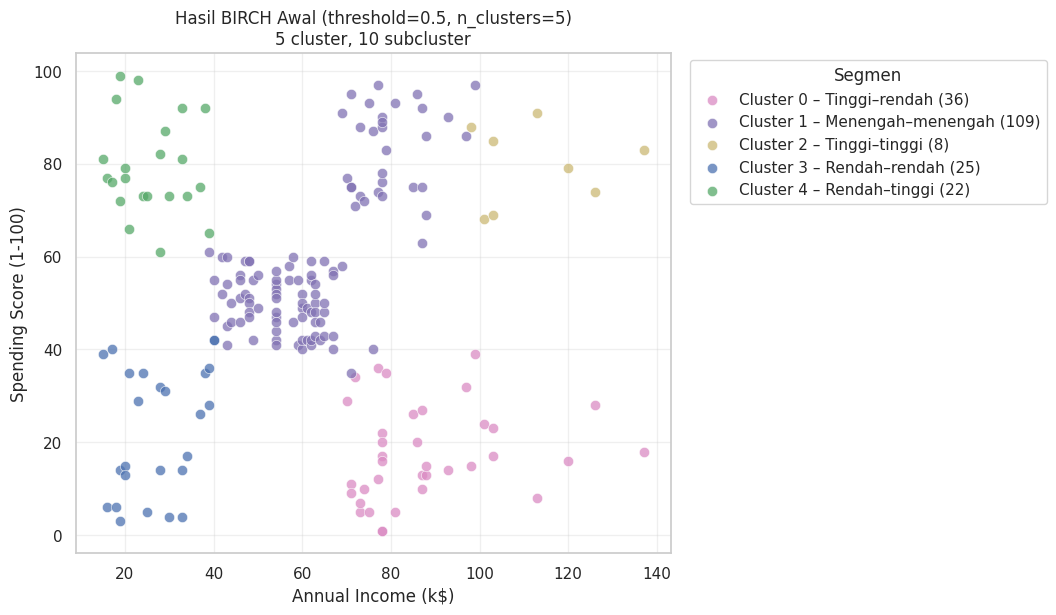

In [14]:
# Scatter plot hasil BIRCH pada ruang fitur asli X
peta_birch = petakan_segmen(X, labels_birch)
warna_birch = warna_plot(labels_birch, peta_birch)

fig, ax = plt.subplots(figsize=(10, 6.5))
for label in sorted(set(labels_birch), key=lambda x: (x == -1, x)):
    mask = labels_birch == label
    nama = peta_birch[label][0]
    warna = WARNA_NOISE if label == -1 else warna_birch[label]
    ax.scatter(
        X.loc[mask, "Annual Income (k$)"],
        X.loc[mask, "Spending Score (1-100)"],
        s=55,
        color=warna,
        alpha=0.75,
        edgecolor="white",
        linewidth=0.5,
        label=f"Cluster {label} – {nama} ({mask.sum()})",
    )

ax.set_title(
    f"Hasil BIRCH Awal (threshold={model_birch.threshold}, n_clusters=5)\n"
    f"{n_clusters_birch} cluster, {n_subcluster_birch} subcluster"
)
ax.set_xlabel("Annual Income (k$)")
ax.set_ylabel("Spending Score (1-100)")
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Segmen")
fig.subplots_adjust(right=0.72)
plt.show()

In [15]:
# Bandingkan beberapa nilai threshold dengan jumlah cluster akhir tetap 5.
# Jumlah subcluster pada CF tree dan Silhouette Score dicatat untuk setiap nilai.
from sklearn.exceptions import ConvergenceWarning
import warnings

threshold_grid = [0.2, 0.3, 0.35, 0.4, 0.5, 0.6, 0.7, 1.0]
hasil_birch = []
for threshold in threshold_grid:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model = Birch(threshold=threshold, branching_factor=50, n_clusters=5)
        label = model.fit_predict(X_scaled)

    n_subcluster = len(model.subcluster_centers_)
    n_cluster = len(set(label))
    silhouette = np.nan
    if n_cluster >= 2 and n_cluster < len(label):
        silhouette = silhouette_score(X_scaled, label)

    hasil_birch.append({
        "threshold": threshold,
        "jumlah_subcluster": n_subcluster,
        "jumlah_cluster": n_cluster,
        "silhouette": silhouette,
    })

birch_grid = pd.DataFrame(hasil_birch)
print("Tabel eksperimen BIRCH dengan n_clusters=5:")
display(birch_grid.round(3))

# Pilih threshold dengan 5 cluster dan silhouette tertinggi
kandidat_birch = birch_grid[
    (birch_grid["jumlah_cluster"] == 5) & birch_grid["silhouette"].notna()
]
baris_birch = kandidat_birch.loc[kandidat_birch["silhouette"].idxmax()]
best_threshold_birch = float(baris_birch["threshold"])

model_birch_best = Birch(
    threshold=best_threshold_birch, branching_factor=50, n_clusters=5
)
labels_birch_best = model_birch_best.fit_predict(X_scaled)
n_subcluster_birch_best = len(model_birch_best.subcluster_centers_)

print(
    f"\nThreshold terpilih: {best_threshold_birch} "
    f"({int(baris_birch['jumlah_cluster'])} cluster, "
    f"{n_subcluster_birch_best} subcluster, "
    f"silhouette={baris_birch['silhouette']:.3f})"
)


Tabel eksperimen BIRCH dengan n_clusters=5:


,threshold,jumlah_subcluster,jumlah_cluster,silhouette
0,0.20,39,5,0.554
1,0.30,23,5,0.478
2,0.35,18,5,0.555
3,0.40,15,5,0.537
4,0.50,10,5,0.414
5,0.60,8,5,0.474
6,0.70,6,5,0.421
7,1.00,4,4,0.389



Threshold terpilih: 0.35 (5 cluster, 18 subcluster, silhouette=0.555)


In [16]:
# Bandingkan hasil BIRCH saat n_clusters tidak ditentukan (n_clusters=None).
# Dalam mode ini, BIRCH mengembalikan label subcluster dari CF tree sebagai cluster akhir.
hasil_birch_auto = []
for threshold in threshold_grid:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model = Birch(threshold=threshold, branching_factor=50, n_clusters=None)
        label = model.fit_predict(X_scaled)

    n_cluster = len(set(label))
    silhouette = np.nan
    if n_cluster >= 2 and n_cluster < len(label):
        silhouette = silhouette_score(X_scaled, label)

    hasil_birch_auto.append({
        "threshold": threshold,
        "jumlah_cluster": n_cluster,
        "silhouette": silhouette,
    })

birch_grid_auto = pd.DataFrame(hasil_birch_auto)
print("Tabel eksperimen BIRCH tanpa menentukan n_clusters (n_clusters=None):")
display(birch_grid_auto.round(3))

# Bandingkan label pada threshold terpilih: n_clusters=5 vs n_clusters=None
model_birch_auto_best = Birch(
    threshold=best_threshold_birch, branching_factor=50, n_clusters=None
)
labels_birch_auto_best = model_birch_auto_best.fit_predict(X_scaled)
ari_birch = adjusted_rand_score(labels_birch_best, labels_birch_auto_best)

print(
    f"Pada threshold={best_threshold_birch}: n_clusters=5 menghasilkan "
    f"{len(set(labels_birch_best))} cluster, sedangkan n_clusters=None menghasilkan "
    f"{len(set(labels_birch_auto_best))} subcluster."
)
print(f"Adjusted Rand Index antara kedua hasil: {ari_birch:.3f}")


Tabel eksperimen BIRCH tanpa menentukan n_clusters (n_clusters=None):


,threshold,jumlah_cluster,silhouette
0,0.20,39,0.401
1,0.30,23,0.414
2,0.35,18,0.398
3,0.40,15,0.414
4,0.50,10,0.477
5,0.60,8,0.517
6,0.70,6,0.486
7,1.00,4,0.389


Pada threshold=0.35: n_clusters=5 menghasilkan 5 cluster, sedangkan n_clusters=None menghasilkan 18 subcluster.
Adjusted Rand Index antara kedua hasil: 0.424


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

**Hasil model awal (`threshold=0,5`, `n_clusters=5`).** BIRCH membentuk **10 subcluster** pada CF tree, lalu menggabungkannya menjadi **5 cluster akhir** dengan Silhouette Score **0,414**. Komposisinya: cluster 0 = 36 titik, cluster 1 = 109 titik, cluster 2 = 8 titik, cluster 3 = 25 titik, dan cluster 4 = 22 titik. Cluster 1 menyerap sebagian besar pelanggan berpendapatan menengah, sedangkan kelompok pendapatan tinggi dengan spending tinggi hanya berisi 8 titik. Artinya, pada threshold 0,5 pemampatan CF tree sudah cukup kasar sehingga dua kelompok yang seharusnya terpisah ikut bergabung.

**Pengaruh `threshold` terhadap jumlah subcluster.** Ketika `n_clusters=None`, jumlah cluster yang dikembalikan sama dengan jumlah subcluster: threshold 0,2 → 39 subcluster, 0,3 → 23, 0,35 → 18, 0,4 → 15, 0,5 → 10, 0,6 → 8, 0,7 → 6, dan 1,0 → 4. Semakin besar threshold, semakin besar radius maksimum subcluster sehingga lebih banyak titik yang digabung ke subcluster yang sama dan pohon CF semakin ringkas. Pada threshold 1,0 jumlah subcluster (4) bahkan lebih kecil daripada `n_clusters=5` yang diminta, sehingga BIRCH hanya menghasilkan 4 cluster akhir (disertai `ConvergenceWarning`).

**Pengaruh `threshold` saat `n_clusters=5`.** Meskipun jumlah cluster akhir dipaksa tetap 5 (kecuali threshold 1,0), kualitas hasilnya berubah karena subcluster yang menjadi input penggabungan berbeda. Silhouette Score berturut-turut: 0,554 (0,2), 0,478 (0,3), **0,555 (0,35)**, 0,537 (0,4), 0,414 (0,5), 0,474 (0,6), 0,421 (0,7), dan 0,389 (1,0 dengan 4 cluster). Nilai tertinggi untuk konfigurasi 5 cluster diperoleh pada **threshold=0,35** dengan 18 subcluster. Pada threshold ini kelima kelompok alami dataset terpisah dengan rapi: pendapatan rendah–spending rendah (23 titik), pendapatan rendah–spending tinggi (21), pendapatan menengah–spending menengah (81), pendapatan tinggi–spending rendah (36), dan pendapatan tinggi–spending tinggi (39).

**Perbedaan BIRCH dan DBSCAN dalam menangani titik jauh.** BIRCH tidak memiliki konsep noise: semua titik harus masuk ke salah satu subcluster, sehingga titik yang jauh tetap dimasukkan ke cluster terdekat dan dapat sedikit menggeser pusat subcluster. DBSCAN sebaliknya menandai titik yang tidak memenuhi kepadatan minimum sebagai noise (label -1); pada konfigurasi terbaiknya terdapat 29 titik noise (14,5%). Karena itu, BIRCH cocok ketika semua pelanggan harus tersegmentasi, sedangkan DBSCAN lebih baik untuk menyaring pencilan.

**Apakah hasil berubah ketika `n_clusters` ditentukan?** Ya. Pada `threshold=0,35`, `n_clusters=None` mengembalikan **18 cluster** (subcluster CF tree) dengan Silhouette Score **0,398**, sedangkan `n_clusters=5` menggabungkan subcluster tersebut menjadi **5 cluster** dengan Silhouette Score **0,555**. Adjusted Rand Index kedua hasil hanya **0,424**, menunjukkan partisi akhirnya cukup berbeda: `n_clusters=None` terlalu granular untuk segmentasi, sedangkan `n_clusters=5` memberi ringkasan yang lebih mudah diinterpretasikan. Namun, penentuan `n_clusters` tidak selalu berhasil: jika jumlah subcluster lebih sedikit daripada `n_clusters` yang diminta (misalnya threshold=1,0), BIRCH tetap mengembalikan jumlah subcluster yang ada.


# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [17]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.
model_gmm = GaussianMixture(
    n_components=5,
    covariance_type="full",
    random_state=42,
)
labels_gmm = model_gmm.fit_predict(X_scaled)
proba_gmm = model_gmm.predict_proba(X_scaled)
n_clusters_gmm = len(set(labels_gmm))

print(
    f"GMM dijalankan dengan n_components={model_gmm.n_components}, "
    f"covariance_type='{model_gmm.covariance_type}', "
    f"random_state={model_gmm.random_state}"
)
print(f"Konvergen: {model_gmm.converged_} setelah {model_gmm.n_iter_} iterasi")
print("Label unik yang terbentuk:", np.unique(labels_gmm))
print(f"Silhouette Score: {silhouette_score(X_scaled, labels_gmm):.3f}")
print(f"BIC: {model_gmm.bic(X_scaled):.3f}")
print(f"AIC: {model_gmm.aic(X_scaled):.3f}")

GMM dijalankan dengan n_components=5, covariance_type='full', random_state=42
Konvergen: True setelah 5 iterasi
Label unik yang terbentuk: [0 1 2 3 4]
Silhouette Score: 0.554
BIC: 1058.652
AIC: 963.001


In [18]:
# Tampilkan jumlah anggota setiap cluster GMM.
print("Jumlah anggota tiap cluster GMM:")
for label in sorted(set(labels_gmm)):
    jumlah = int((labels_gmm == label).sum())
    print(f"  Cluster {label}: {jumlah} ({jumlah / len(labels_gmm) * 100:.1f}%)")

print(f"\nJumlah cluster: {n_clusters_gmm}")

# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
proba_df = pd.DataFrame(
    proba_gmm,
    columns=[f"prob_cluster_{i}" for i in range(model_gmm.n_components)],
    index=X.index,
)
proba_df["cluster"] = labels_gmm
proba_df["max_prob"] = proba_gmm.max(axis=1)

print("\nContoh probabilitas keanggotaan (10 baris pertama):")
display(proba_df.head(10).round(3))

# Titik dengan probabilitas maksimum rendah berada di perbatasan antarkomponen.
batas_keyakinan = 0.7
tidak_yakin = proba_df[proba_df["max_prob"] < batas_keyakinan].sort_values("max_prob")
print(
    f"\nTitik dengan probabilitas maksimum < {batas_keyakinan}: "
    f"{len(tidak_yakin)} dari {len(proba_df)} titik"
)
print(
    f"Rata-rata probabilitas maksimum: {proba_df['max_prob'].mean():.3f}; "
    f"median: {proba_df['max_prob'].median():.3f}; "
    f"minimum: {proba_df['max_prob'].min():.3f}"
)

print("\nTitik yang paling tidak yakin (termasuk fitur asli):")
tidak_yakin_asli = X.loc[tidak_yakin.index].copy()
tidak_yakin_asli["cluster"] = tidak_yakin["cluster"]
tidak_yakin_asli["max_prob"] = tidak_yakin["max_prob"]
display(tidak_yakin_asli.head(10).round(3))

Jumlah anggota tiap cluster GMM:
  Cluster 0: 84 (42.0%)
  Cluster 1: 39 (19.5%)
  Cluster 2: 21 (10.5%)
  Cluster 3: 33 (16.5%)
  Cluster 4: 23 (11.5%)

Jumlah cluster: 5

Contoh probabilitas keanggotaan (10 baris pertama):


,prob_cluster_0,prob_cluster_1,prob_cluster_2,prob_cluster_3,prob_cluster_4,cluster,max_prob
0,0.000,0.0,0.001,0.0,0.999,4,0.999
1,0.000,0.0,1.000,0.0,0.000,2,1.000
2,0.000,0.0,0.000,0.0,1.000,4,1.000
3,0.000,0.0,1.000,0.0,0.000,2,1.000
4,0.000,0.0,0.002,0.0,0.998,4,0.998
5,0.000,0.0,1.000,0.0,0.000,2,1.000
6,0.000,0.0,0.000,0.0,1.000,4,1.000
7,0.000,0.0,1.000,0.0,0.000,2,1.000
8,0.000,0.0,0.000,0.0,1.000,4,1.000
9,0.001,0.0,0.998,0.0,0.000,2,0.998



Titik dengan probabilitas maksimum < 0.7: 4 dari 200 titik
Rata-rata probabilitas maksimum: 0.983; median: 1.000; minimum: 0.503

Titik yang paling tidak yakin (termasuk fitur asli):


,Annual Income (k$),Spending Score (1-100),cluster,max_prob
124,70,29,3,0.503
48,40,42,0,0.611
49,40,42,0,0.611
27,28,61,2,0.675


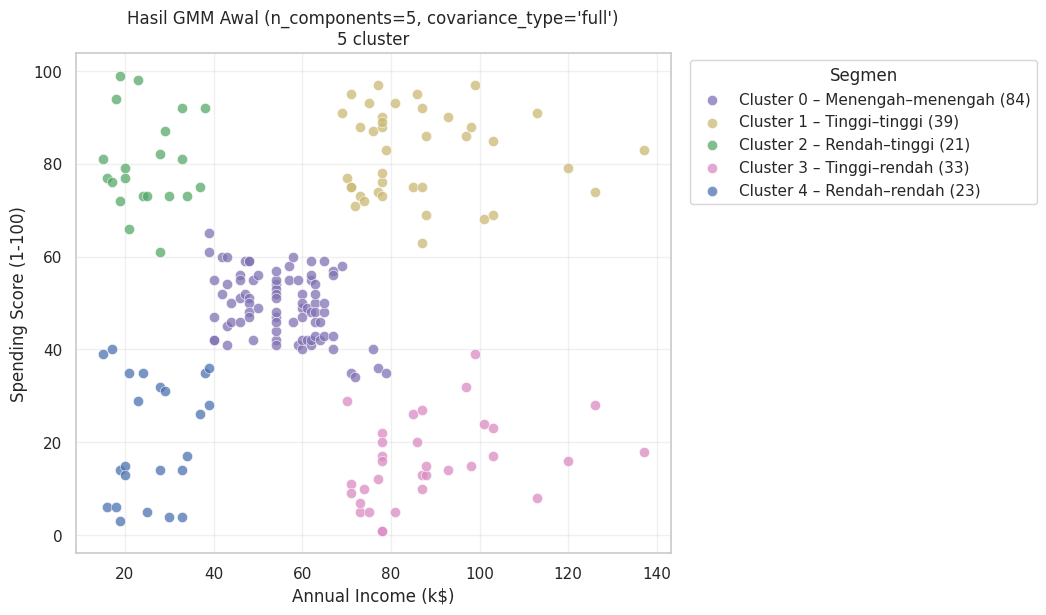

In [19]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
peta_gmm = petakan_segmen(X, labels_gmm)
warna_gmm = warna_plot(labels_gmm, peta_gmm)

fig, ax = plt.subplots(figsize=(10, 6.5))
for label in sorted(set(labels_gmm)):
    mask = labels_gmm == label
    nama = peta_gmm[label][0]
    warna = warna_gmm[label]
    ax.scatter(
        X.loc[mask, "Annual Income (k$)"],
        X.loc[mask, "Spending Score (1-100)"],
        s=55,
        color=warna,
        alpha=0.75,
        edgecolor="white",
        linewidth=0.5,
        label=f"Cluster {label} – {nama} ({mask.sum()})",
    )

ax.set_title(
    f"Hasil GMM Awal (n_components={model_gmm.n_components}, "
    f"covariance_type='{model_gmm.covariance_type}')\n"
    f"{n_clusters_gmm} cluster"
)
ax.set_xlabel("Annual Income (k$)")
ax.set_ylabel("Spending Score (1-100)")
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Segmen")
fig.subplots_adjust(right=0.72)
plt.show()

In [20]:
# Bandingkan beberapa nilai n_components (2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
hasil_gmm = []
for k in range(2, 9):
    model = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
    )
    label = model.fit_predict(X_scaled)
    n_cluster = len(set(label))
    silhouette = np.nan
    if 2 <= n_cluster < len(label):
        silhouette = silhouette_score(X_scaled, label)

    hasil_gmm.append({
        "n_components": k,
        "jumlah_cluster": n_cluster,
        "silhouette": silhouette,
        "bic": model.bic(X_scaled),
        "aic": model.aic(X_scaled),
        "n_iter": model.n_iter_,
        "konvergen": model.converged_,
    })

gmm_grid = pd.DataFrame(hasil_gmm)
print("Tabel eksperimen GMM (covariance_type='full', random_state=42):")
display(gmm_grid.round(3))

# BIC minimum dan silhouette maksimum dipakai sebagai pertimbangan pemilihan model.
baris_bic = gmm_grid.loc[gmm_grid["bic"].idxmin()]
baris_silhouette = gmm_grid.loc[gmm_grid["silhouette"].idxmax()]

print(
    f"BIC terendah: n_components={int(baris_bic['n_components'])} "
    f"(BIC={baris_bic['bic']:.3f})"
)
print(
    f"Silhouette tertinggi: n_components={int(baris_silhouette['n_components'])} "
    f"(silhouette={baris_silhouette['silhouette']:.3f})"
)

best_n_components = int(baris_bic["n_components"])
model_gmm_best = GaussianMixture(
    n_components=best_n_components,
    covariance_type="full",
    random_state=42,
)
labels_gmm_best = model_gmm_best.fit_predict(X_scaled)
proba_gmm_best = model_gmm_best.predict_proba(X_scaled)

print(
    f"\nModel GMM terpilih: n_components={best_n_components}, "
    f"{len(set(labels_gmm_best))} cluster, "
    f"silhouette={silhouette_score(X_scaled, labels_gmm_best):.3f}, "
    f"BIC={model_gmm_best.bic(X_scaled):.3f}"
)

Tabel eksperimen GMM (covariance_type='full', random_state=42):


,n_components,jumlah_cluster,silhouette,bic,aic,n_iter,konvergen
0,2,2,0.379,1153.905,1117.623,6,True
1,3,3,0.430,1151.718,1095.647,8,True
2,4,4,0.413,1103.790,1027.929,8,True
3,5,5,0.554,1058.652,963.001,5,True
4,6,6,0.517,1074.683,959.242,5,True
5,7,7,0.509,1087.329,952.098,6,True
6,8,8,0.430,1102.371,947.350,8,True


BIC terendah: n_components=5 (BIC=1058.652)
Silhouette tertinggi: n_components=5 (silhouette=0.554)

Model GMM terpilih: n_components=5, 5 cluster, silhouette=0.554, BIC=1058.652


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

**Hasil model awal (`n_components=5`, `covariance_type='full'`, `random_state=42`).** Model konvergen setelah **5 iterasi** dan membentuk **5 cluster** dengan komposisi: cluster 0 = **84 titik (42,0%)**, cluster 1 = **39 titik (19,5%)**, cluster 2 = **21 titik (10,5%)**, cluster 3 = **33 titik (16,5%)**, dan cluster 4 = **23 titik (11,5%)**. Silhouette Score model ini **0,554**, BIC **1058,652**, dan AIC **963,001**.

**Arti probabilitas keanggotaan.** `predict_proba` menghasilkan probabilitas posterior setiap titik terhadap tiap komponen Gaussian. Nilai tertinggi menentukan label cluster, tetapi besarannya menunjukkan seberapa yakin titik tersebut berada di cluster itu. Pada model ini rata-rata probabilitas maksimum **0,983** dan median **0,9996**; **196 dari 200 titik (98%)** memiliki probabilitas maksimum ≥ 0,7. Hanya **4 titik** yang berada di bawah 0,7, dengan nilai terendah **0,503** pada pelanggan berpendapatan 70 k$ dan spending 29 (cluster 3). Titik-titik seperti (40, 42) dan (28, 61) berada di perbatasan antarkomponen sehingga assignment-nya relatif tidak pasti. Jadi, GMM tidak hanya memberi label keras, tetapi juga derajat keanggotaan yang berguna untuk analisis lanjutan.

**Pengaruh `n_components`.** Silhouette Score berturut-turut untuk k = 2 sampai 8 adalah **0,379; 0,430; 0,413; 0,554; 0,517; 0,509; 0,430**. BIC turun dari **1153,905** (k=2) menjadi **1058,652** pada k=5, lalu naik lagi menjadi **1074,683** (k=6), **1087,329** (k=7), dan **1102,371** (k=8). Artinya, k=5 memberi keseimbangan terbaik antara kecocokan dan kompleksitas menurut BIC. AIC terus turun sampai k=8 (**947,350**), karena penalti AIC lebih ringan terhadap jumlah parameter; ini menunjukkan likelihood masih membaik dengan komponen tambahan, tetapi model menjadi lebih kompleks dan belum tentu lebih berguna untuk segmentasi.

**Mengapa jumlah cluster GMM harus ditentukan sebelum model dilatih?** GMM adalah model parametrik dengan jumlah komponen tetap. EM hanya mengestimasi parameter (bobot campuran, mean, dan kovarians) untuk jumlah komponen yang diberikan; algoritma ini tidak memiliki kriteria kepadatan seperti DBSCAN untuk menemukan jumlah cluster sendiri. Karena itu, `n_components` harus ditentukan lebih dahulu, lalu dipilih menggunakan BIC/AIC, Silhouette Score, dan pertimbangan domain.

**Apakah Silhouette Score tertinggi juga memiliki BIC terendah?** Pada eksperimen ini **ya**: keduanya memilih `n_components=5`. Namun hal itu tidak selalu terjadi. Silhouette mengukur pemisahan dan kekompakan cluster, sedangkan BIC mengukur kecocokan likelihood dengan penalti jumlah parameter; keduanya bisa memberi urutan berbeda, terutama jika bentuk cluster tidak bulat atau ukurannya tidak seimbang.


# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [21]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.
def evaluasi_clustering(X_eval, labels, nama_model, hapus_noise=False):
    labels = np.asarray(labels)
    mask = labels != -1 if hapus_noise else np.ones(len(labels), dtype=bool)
    X_used = X_eval[mask]
    labels_used = labels[mask]
    n_clusters = len(np.unique(labels_used))

    hasil = {
        "model": nama_model,
        "jumlah_cluster": n_clusters,
        "jumlah_noise": int((labels == -1).sum()) if hapus_noise else 0,
        "n_dievaluasi": int(mask.sum()),
        "silhouette": np.nan,
        "davies_bouldin": np.nan,
        "calinski_harabasz": np.nan,
    }

    if 2 <= n_clusters < len(labels_used):
        hasil["silhouette"] = silhouette_score(X_used, labels_used)
        hasil["davies_bouldin"] = davies_bouldin_score(X_used, labels_used)
        hasil["calinski_harabasz"] = calinski_harabasz_score(X_used, labels_used)

    return hasil

In [22]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
baris_evaluasi = [
    evaluasi_clustering(
        X_scaled, labels_dbscan_best, "DBSCAN", hapus_noise=True
    ),
    evaluasi_clustering(
        X_scaled, labels_birch_best, "BIRCH", hapus_noise=False
    ),
    evaluasi_clustering(
        X_scaled, labels_gmm_best, "GMM", hapus_noise=False
    ),
]

tabel_evaluasi = pd.DataFrame(baris_evaluasi)
tabel_evaluasi = tabel_evaluasi[[
    "model",
    "jumlah_cluster",
    "jumlah_noise",
    "n_dievaluasi",
    "silhouette",
    "davies_bouldin",
    "calinski_harabasz",
]]

print("Ringkasan evaluasi model terbaik:")
display(tabel_evaluasi.round(3))

print(
    "Catatan: metrik DBSCAN dihitung hanya pada titik non-noise "
    f"({int((labels_dbscan_best != -1).sum())} dari {len(labels_dbscan_best)} titik), "
    "sedangkan BIRCH dan GMM dievaluasi pada seluruh titik."
)

Ringkasan evaluasi model terbaik:


,model,jumlah_cluster,jumlah_noise,n_dievaluasi,silhouette,davies_bouldin,calinski_harabasz
0,DBSCAN,5,29,171,0.574,0.483,245.144
1,BIRCH,5,0,200,0.555,0.570,248.033
2,GMM,5,0,200,0.554,0.576,244.940


Catatan: metrik DBSCAN dihitung hanya pada titik non-noise (171 dari 200 titik), sedangkan BIRCH dan GMM dievaluasi pada seluruh titik.


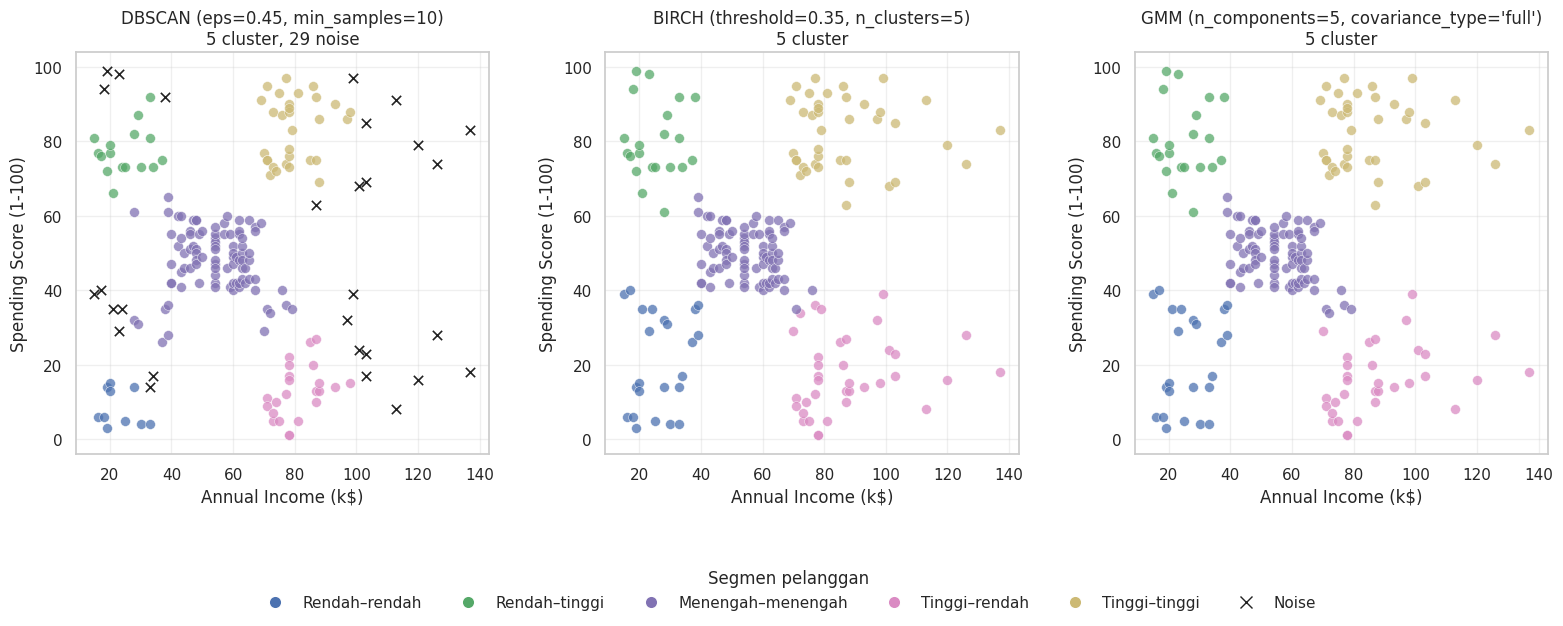

In [23]:
# Buat tiga scatter plot dalam satu baris subplot: DBSCAN, BIRCH, dan GMM.
# Warna segmen dibuat sama antar-algoritma agar legenda tidak menyesatkan.
panel = [
    (
        f"DBSCAN (eps={best_eps}, min_samples={best_min_samples})",
        labels_dbscan_best,
        "DBSCAN",
    ),
    (
        f"BIRCH (threshold={best_threshold_birch}, n_clusters=5)",
        labels_birch_best,
        "BIRCH",
    ),
    (
        f"GMM (n_components={model_gmm_best.n_components}, covariance_type='full')",
        labels_gmm_best,
        "GMM",
    ),
]

fig, axes = plt.subplots(1, 3, figsize=(19, 6.8))
for ax, (judul, labels, nama_model) in zip(axes, panel):
    peta = petakan_segmen(X, labels)
    warna_map = warna_plot(labels, peta)
    for label in sorted(set(labels), key=lambda x: (x == -1, x)):
        mask = labels == label
        nama = peta[label][0]
        warna = WARNA_NOISE if label == -1 else warna_map[label]
        if label == -1:
            ax.scatter(
                X.loc[mask, "Annual Income (k$)"],
                X.loc[mask, "Spending Score (1-100)"],
                s=45, c=warna, marker="x", linewidths=1.2,
                label="Noise",
            )
        else:
            ax.scatter(
                X.loc[mask, "Annual Income (k$)"],
                X.loc[mask, "Spending Score (1-100)"],
                s=50, color=warna, alpha=0.75,
                edgecolor="white", linewidth=0.4,
            )

    n_cluster = len(set(labels) - {-1})
    n_noise = int((labels == -1).sum())
    ringkasan = f"{n_cluster} cluster"
    if nama_model == "DBSCAN":
        ringkasan += f", {n_noise} noise"
    ax.set_title(f"{judul}\n{ringkasan}")
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.grid(True, alpha=0.3)

# Legenda bersama: warna yang sama selalu berarti segmen yang sama.
nama_tersedia = []
for _, labels, _ in panel:
    for nama, _ in petakan_segmen(X, labels).values():
        if nama != "Noise" and nama not in nama_tersedia:
            nama_tersedia.append(nama)
urutan_segmen = [
    "Rendah–rendah", "Rendah–menengah", "Rendah–tinggi",
    "Menengah–rendah", "Menengah–menengah", "Menengah–tinggi",
    "Tinggi–rendah", "Tinggi–menengah", "Tinggi–tinggi",
]
nama_tersedia = [nama for nama in urutan_segmen if nama in nama_tersedia]

handles = [
    Line2D(
        [0], [0], marker="o", color="w",
        markerfacecolor=WARNA_SEGMEN[nama], markersize=9,
        label=nama,
    )
    for nama in nama_tersedia
]
handles.append(
    Line2D(
        [0], [0], marker="x", color=WARNA_NOISE,
        markersize=9, linestyle="None", label="Noise",
    )
)
fig.legend(
    handles=handles, loc="lower center", ncol=6,
    title="Segmen pelanggan", frameon=False,
    bbox_to_anchor=(0.5, 0.02),
)
fig.subplots_adjust(bottom=0.27, top=0.86, wspace=0.28)
plt.show()

In [24]:
# Buat profil cluster pada fitur asli.
def tabel_profil(X_asli, labels, nama_model):
    data = X_asli.copy()
    data["cluster"] = labels
    profil = data.groupby("cluster").agg(
        jumlah=("Annual Income (k$)", "size"),
        median_pendapatan=("Annual Income (k$)", "median"),
        rata_rata_pendapatan=("Annual Income (k$)", "mean"),
        median_spending=("Spending Score (1-100)", "median"),
        rata_rata_spending=("Spending Score (1-100)", "mean"),
    )
    peta = petakan_segmen(X_asli, labels)
    profil.insert(0, "segmen", [peta[label][0] for label in profil.index])
    profil.insert(0, "model", nama_model)
    return profil


profil_dbscan = tabel_profil(X, labels_dbscan_best, "DBSCAN")
profil_birch = tabel_profil(X, labels_birch_best, "BIRCH")
profil_gmm = tabel_profil(X, labels_gmm_best, "GMM")

print("Profil cluster DBSCAN (label -1 = noise):")
display(profil_dbscan.round(2))

print("\nProfil cluster BIRCH:")
display(profil_birch.round(2))

print("\nProfil cluster GMM:")
display(profil_gmm.round(2))

Profil cluster DBSCAN (label -1 = noise):


,model,segmen,jumlah,median_pendapatan,rata_rata_pendapatan,median_spending,rata_rata_spending
cluster,,,,,,,
-1,DBSCAN,Noise,29,99.0,77.69,39.0,51.93
0,DBSCAN,Rendah–tinggi,16,24.5,25.06,76.5,77.31
1,DBSCAN,Rendah–rendah,10,20.0,22.80,6.0,8.40
2,DBSCAN,Menengah–menengah,92,54.0,54.15,48.5,48.10
3,DBSCAN,Tinggi–tinggi,30,78.0,79.53,86.0,83.13
4,DBSCAN,Tinggi–rendah,23,78.0,80.96,13.0,12.78



Profil cluster BIRCH:


,model,segmen,jumlah,median_pendapatan,rata_rata_pendapatan,median_spending,rata_rata_spending
cluster,,,,,,,
0,BIRCH,Tinggi–tinggi,39,79.0,86.54,83.0,82.13
1,BIRCH,Rendah–rendah,23,25.0,26.30,17.0,20.91
2,BIRCH,Tinggi–rendah,36,83.0,87.75,16.0,17.58
3,BIRCH,Rendah–tinggi,21,24.0,25.10,77.0,80.05
4,BIRCH,Menengah–menengah,81,54.0,54.89,50.0,49.90



Profil cluster GMM:


,model,segmen,jumlah,median_pendapatan,rata_rata_pendapatan,median_spending,rata_rata_spending
cluster,,,,,,,
0,GMM,Menengah–menengah,84,55.5,55.64,49.5,49.37
1,GMM,Tinggi–tinggi,39,79.0,86.54,83.0,82.13
2,GMM,Rendah–tinggi,21,24.0,25.10,77.0,80.05
3,GMM,Tinggi–rendah,33,86.0,88.82,15.0,16.00
4,GMM,Rendah–rendah,23,25.0,26.30,17.0,20.91


### Ringkasan Perbandingan

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak; jumlah cluster muncul dari kepadatan titik | Ya untuk partisi akhir (`n_clusters`); jika `n_clusters=None`, hasilnya berupa subcluster CF tree | Ya (`n_components`); EM tidak memilih jumlah komponen sendiri |
| Dapat memberi label noise secara eksplisit? | Ya, label `-1` | Tidak; semua titik dimasukkan ke subcluster/cluster | Tidak; semua titik mendapat probabilitas keanggotaan |
| Parameter yang paling memengaruhi hasil | `eps`, `min_samples` | `threshold`, `n_clusters`, `branching_factor` | `n_components`, `covariance_type`, inisialisasi/`random_state` |
| Bentuk cluster yang dapat dimodelkan | Cluster berbasis kepadatan, dapat berbentuk tidak beraturan/non-convex | Subcluster kecil yang relatif bulat/elipsoid, lalu digabung menjadi cluster akhir | Komponen Gaussian berbentuk elips sesuai matriks kovarians |
| Kelebihan | Dapat menemukan noise/outlier; tidak perlu menentukan K; cocok untuk cluster tidak beraturan | Ringkas dan cepat; cocok untuk data besar; semua titik tersegmentasi | Memberi soft assignment dan probabilitas; model probabilistik fleksibel |
| Kekurangan | Sensitif terhadap `eps` dan `min_samples`; noise bisa banyak; sulit jika kepadatan tidak seragam | Perlu K untuk partisi akhir; asumsi subcluster relatif bulat; tidak ada noise eksplisit | Perlu K; asumsi Gaussian; sensitif terhadap inisialisasi dan bentuk kovarians |

# 7. Analisis

### Analisis

1. **Mengapa fitur perlu di-scaling sebelum clustering?** `Annual Income (k$)` dan `Spending Score (1-100)` memiliki satuan dan rentang berbeda. DBSCAN dan BIRCH menghitung jarak Euclidean, sehingga fitur dengan varians/rentang lebih besar bisa mendominasi jarak dan membuat `eps` atau `threshold` tidak adil untuk kedua fitur. GMM juga mengestimasi matriks kovarians; skala yang tidak sebanding membuat estimasi dan interpretasi parameter kurang stabil. Setelah `StandardScaler`, rata-rata tiap fitur ≈ 0 dan simpangan baku ≈ 1, sehingga satu satuan jarak berarti satu simpangan baku pada masing-masing fitur.

2. **Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?** Dengan `min_samples=5`, menaikkan `eps` dari 0,30 ke 0,55 mengurangi jumlah cluster dari 7 menjadi 1 dan noise dari 35 menjadi 7, karena jangkauan tetangga makin besar sehingga cluster yang berdekatan bergabung. Sebaliknya, menaikkan `min_samples` membuat syarat titik inti lebih ketat: pada `eps=0,30`, `min_samples=7` menghasilkan 4 cluster/72 noise dan `min_samples=10` menghasilkan 4 cluster/88 noise (44%). Efeknya tidak selalu monoton; pada `eps=0,45`, `min_samples=5` memberi 3 cluster/11 noise, sedangkan `min_samples=10` memberi 5 cluster/29 noise karena beberapa “jembatan” antarkelompok hilang dan kelompok yang sebelumnya menyatu terpisah kembali.

3. **Bagaimana `threshold` dan `n_clusters` memengaruhi BIRCH?** Semakin besar `threshold`, semakin besar radius maksimum subcluster sehingga CF tree makin ringkas: jumlah subcluster turun dari 39 (threshold 0,2) menjadi 4 (threshold 1,0). Jika `n_clusters=5`, jumlah cluster akhir biasanya dipaksa lima, tetapi kualitasnya berubah karena subcluster yang digabung berbeda; Silhouette Score tertinggi diperoleh pada **threshold=0,35** (0,555, 18 subcluster). Pada threshold 1,0 hanya terbentuk 4 subcluster, sehingga BIRCH mengembalikan 4 cluster dan memunculkan `ConvergenceWarning`. Ketika `n_clusters=None` pada threshold 0,35, BIRCH mengembalikan 18 subcluster (silhouette 0,398); ARI terhadap hasil 5 cluster hanya **0,424**, jadi penentuan `n_clusters` sangat memengaruhi partisi akhir.

4. **Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?** Probabilitas keanggotaan adalah probabilitas posterior bahwa suatu titik berasal dari setiap komponen Gaussian. EM bekerja bergantian: langkah **E** menghitung tanggung jawab/probabilitas setiap titik terhadap komponen, lalu langkah **M** memperbarui bobot, mean, dan kovarians berdasarkan tanggung jawab tersebut. Label akhir diambil dari probabilitas terbesar. Nilai mendekati 1 berarti assignment sangat yakin; nilai mendekati 0,5 berarti titik berada di perbatasan dua komponen. Pada model ini 98% titik memiliki probabilitas maksimum ≥ 0,7, dan hanya 4 titik yang relatif tidak pasti.

5. **Model mana yang paling mudah diinterpretasikan?** **BIRCH** paling mudah dibaca karena menghasilkan lima segmen yang rapi dan semua 200 pelanggan mendapat label. **GMM** juga mudah diinterpretasikan dan lebih kaya karena memberi probabilitas keanggotaan, sehingga titik perbatasan dapat dianalisis terpisah. **DBSCAN** lebih tepat dipakai untuk menemukan outlier: 29 titik (14,5%) diberi label noise, dan cluster yang tersisa sangat bersih, tetapi segmentasinya tidak mencakup seluruh pelanggan.

6. **Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama?** Tidak sepenuhnya. DBSCAN memiliki **Silhouette Score tertinggi (0,574)** dan **Davies-Bouldin terendah (0,483)**, sedangkan BIRCH memiliki **Calinski-Harabasz tertinggi (248,033)**; GMM berada dekat keduanya (silhouette 0,554; Davies-Bouldin 0,576; Calinski-Harabasz 244,940). Perbandingan ini tidak sepenuhnya adil karena metrik DBSCAN dihitung hanya pada 171 titik non-noise, sedangkan BIRCH dan GMM dievaluasi pada 200 titik. Metrik internal juga cenderung menyukai cluster yang kompak dan terpisah secara geometris, sehingga bisa menguntungkan hasil yang membuang titik sulit. Karena BIRCH dan GMM menghasilkan partisi yang hampir sama (ARI ≈ 0,955), perbedaan skor kecil di antara keduanya tidak terlalu bermakna.

7. **Karakteristik cluster berdasarkan median pendapatan dan spending.**
   - **DBSCAN:** cluster 0 = pendapatan rendah–spending tinggi (16 titik; median 24,5 k$/76,5), cluster 1 = rendah–rendah (10; 20/6), cluster 2 = menengah–menengah (92; 54/48,5), cluster 3 = tinggi–tinggi (30; 78/86), cluster 4 = tinggi–rendah (23; 78/13). Noise (29 titik; median 99/39) sebagian besar adalah pelanggan berpendapatan tinggi dengan spending menengah serta titik di perbatasan kelompok.
   - **BIRCH:** cluster 0 = tinggi–tinggi (39; 79/83), cluster 1 = rendah–rendah (23; 25/17), cluster 2 = tinggi–rendah (36; 83/16), cluster 3 = rendah–tinggi (21; 24/77), cluster 4 = menengah–menengah (81; 54/50).
   - **GMM:** cluster 0 = menengah–menengah (84; 55,5/49,5), cluster 1 = tinggi–tinggi (39; 79/83), cluster 2 = rendah–tinggi (21; 24/77), cluster 3 = tinggi–rendah (33; 86/15), cluster 4 = rendah–rendah (23; 25/17).

   Nama deskriptif yang bisa dipakai: **“Rendah–rendah” = pelanggan hemat**, **“Rendah–tinggi” = pelanggan impulsif**, **“Menengah–menengah” = pelanggan standar**, **“Tinggi–rendah” = pelanggan bijak/frugal**, dan **“Tinggi–tinggi” = pelanggan premium**. Titik noise DBSCAN dapat disebut **pelanggan tidak tipikal/perbatasan**.

8. **Apa keterbatasan penggunaan dua fitur dan dataset kecil?** Hanya dua fitur yang dipakai, sehingga informasi usia, gender, dan perilaku lain tidak masuk; segmentasi bisa berubah jika fitur ditambah. Dataset hanya 200 baris, sehingga hasil sensitif terhadap pencilan dan sulit digeneralisasi. GMM mengasumsikan komponen Gaussian, BIRCH mengasumsikan subcluster relatif bulat, dan DBSCAN sangat bergantung pada `eps`/`min_samples`. Metrik internal tidak memakai label ground truth, sehingga “cluster terbaik” secara metrik belum tentu paling berguna secara bisnis. Karena itu, hasil sebaiknya divalidasi pada data baru dan dikaitkan dengan tujuan bisnis.

# 8. Kesimpulan dan Saran

### Kesimpulan dan Saran

- **Algoritma yang memberi hasil paling berguna:** untuk segmentasi seluruh pelanggan, **GMM** (atau BIRCH yang hasilnya hampir sama) paling berguna karena semua 200 pelanggan mendapat segmen dan lima kelompok yang terbentuk sesuai intuisi bisnis: rendah–rendah, rendah–tinggi, menengah–menengah, tinggi–rendah, dan tinggi–tinggi. GMM dipilih karena BIC dan Silhouette Score sama-sama optimal pada `n_components=5`, serta memberi probabilitas keanggotaan untuk menandai pelanggan yang berada di perbatasan. DBSCAN tetap berguna sebagai **pendeteksi outlier**: 29 titik (14,5%) ditandai noise, tetapi karena tidak semua pelanggan tersegmentasi, hasilnya kurang cocok sebagai satu-satunya dasar segmentasi.
- **Parameter yang dipilih dan alasannya:** GMM menggunakan `n_components=5`, `covariance_type='full'`, dan `random_state=42` karena memberi BIC terendah (1058,652) dan Silhouette Score tertinggi (0,554) di antara k=2 sampai 8. BIRCH menggunakan `threshold=0,35`, `branching_factor=50`, dan `n_clusters=5` karena memberi Silhouette Score tertinggi (0,555) dengan 18 subcluster. DBSCAN menggunakan `eps=0,45` dan `min_samples=10` karena menghasilkan 5 cluster dengan Silhouette Score tertinggi (0,574) pada titik non-noise.
- **Perbedaan utama DBSCAN, BIRCH, dan EM/GMM:** DBSCAN berbasis kepadatan, tidak perlu menentukan K, dan dapat memberi label noise. BIRCH meringkas data menjadi subcluster dalam CF tree lalu menggabungkannya; perlu K untuk partisi akhir dan tidak punya konsep noise eksplisit. GMM/EM berbasis probabilitas, memodelkan data sebagai campuran Gaussian, memberi soft assignment, tetapi perlu menentukan K dan mengasumsikan bentuk distribusi.
- **Eksperimen lanjutan:** menambahkan `Age` dan `Gender` (dengan encoding yang tepat), mencoba kombinasi fitur lain, menggunakan `RobustScaler` atau transformasi, serta memeriksa stabilitas cluster dengan beberapa random seed dan bootstrap. Untuk DBSCAN dapat dicoba `k-distance plot`, HDBSCAN, atau `eps` yang lebih halus; untuk BIRCH dapat dicoba variasi `branching_factor` dan `threshold`; untuk GMM dapat dicoba `covariance_type` lain, `n_init` lebih besar, atau inisialisasi dari K-Means. Validasi dengan data baru atau metrik bisnis tetap diperlukan.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)